# 3Di results with pyramids-mesh

**3Di** is a hydrodynamic flood model whose results NetCDF stores values on a staggered sub-grid rather than an explicit polygon mesh. The pyramids-mesh 3Di driver is a *needs-mesh* driver: it **reconstructs the 2D cell grid itself** from the file's geometry arrays, then presents it as a standard `UgridDataset`.

(3Di files can also carry a coupled 1D network; pyramids represents the 2D mesh and warns that the 1D part is dropped.)

## Setup

In [1]:
from pathlib import Path
import numpy as np
from pyramids.netcdf.ugrid import UgridDataset

# Paths are relative to THIS notebook (docs/examples/), never the repo root.
# read_file takes a pathlib.Path - pass Path objects, never str().
DATA = Path("../../examples/data")
DATA.resolve()
import matplotlib.pyplot as plt

## What is on disk

In [2]:
for p in sorted((DATA / "3di").iterdir()):
    print(p.name, f"({p.stat().st_size:,} bytes)")

results_3di.nc (121,380 bytes)


## Quickstart read

Pass `driver="3di"` explicitly. The driver rebuilds the 2D grid and loads the `Mesh2D_*` result variables. The `UserWarning` about a coupled 1D network is expected for this file.

In [3]:
ds = UgridDataset.read_file(DATA / "3di" / "results_3di.nc", driver="3di")
ds

C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:483: UserWarning: '..\\..\\examples\\data\\3di\\results_3di.nc' also carries a coupled 1D network (Mesh1D*), which pyramids cannot represent alongside the 2D mesh: there is no Network1d coupling relation, so the 1D part is not in this result
  parsed = self._parse(path, lazy=lazy)


UgridDataset(mesh='mesh2d', n_node=25, n_face=16, n_edge=0, variables=['Mesh2D_q_lat', 'Mesh2D_rain', 'Mesh2D_s1', 'Mesh2D_su', 'Mesh2D_ucx', 'Mesh2D_ucy', 'Mesh2D_vol'])

In [4]:
# reading switches matplotlib to Agg for headless safety; let cleopatra
# pick the notebook backend (inline) so the plots below embed
from cleopatra.config import Config
Config.set_matplotlib_backend()

'inline'

The result variables are water surface level (`Mesh2D_s1`), velocity components (`Mesh2D_ucx`, `Mesh2D_ucy`), cell volume (`Mesh2D_vol`) and forcings (`Mesh2D_rain`, `Mesh2D_q_lat`).

## Explore the dataset

A `UgridDataset` wraps a UGRID-style unstructured mesh plus any data variables that ride on it. The scalar properties below describe the grid at a glance: how many nodes and faces it has, its coordinate reference system, and its spatial extent.

The reconstructed grid here is a compact 4x4 block of quad cells (25 nodes, 16 faces).

In [5]:
print("n_node:", ds.n_node)
print("n_face:", ds.n_face)
print("crs:   ", ds.crs)
print("epsg:  ", ds.epsg)
print("bounds:", ds.bounds)  # (xmin, ymin, xmax, ymax)

n_node: 25
n_face: 16
crs:    None
epsg:   None
bounds: (0.0, 0.0, 24.0, 24.0)


`crs`/`epsg` are often `None`: many hydraulic-model result files store coordinates without an embedded CRS, so pyramids reports the geometry faithfully and leaves georeferencing to you. The `bounds` tuple is the mesh envelope in the file's own coordinate units.

### Data variables

`data_variable_names` lists every field attached to the mesh. These are the real model results - water levels, depths, velocities - that make a results file worth reading.

In [6]:
ds.data_variable_names

['Mesh2D_q_lat',
 'Mesh2D_rain',
 'Mesh2D_s1',
 'Mesh2D_su',
 'Mesh2D_ucx',
 'Mesh2D_ucy',
 'Mesh2D_vol']

`summary()` returns a tidy `pandas.DataFrame` of per-variable statistics (count, min, max, mean, std) - a quick sanity check on magnitudes and fill values.

In [7]:
ds.summary()

,count,min,max,mean,std
variable,,,,,
Mesh2D_q_lat,112,0.000000e+00,0.000000,0.000000,0.000000
Mesh2D_rain,112,0.000000e+00,0.000000,0.000000,0.000000
Mesh2D_s1,112,-9.999000e+03,0.020815,-1428.424310,3498.922874
Mesh2D_su,112,1.000000e-08,36.000000,30.857143,12.597376
Mesh2D_ucx,112,-4.557600e-02,0.053289,0.002722,0.013982
Mesh2D_ucy,112,-4.555400e-02,0.054605,0.004917,0.015581
Mesh2D_vol,112,0.000000e+00,0.749338,0.153423,0.158231


## The Mesh2d geometry

`ds.mesh` is a `Mesh2d`: the topology the data variables are defined on. Nodes carry the `(x, y)` coordinates; `face_node_connectivity` says which nodes form each face (a row per face, padded to the maximum vertex count).

In [8]:
mesh = ds.mesh
nx, ny = np.asarray(mesh.node_x), np.asarray(mesh.node_y)
fnc = np.asarray(mesh.face_node_connectivity.data)
print("node_x:", nx.shape, " node_y:", ny.shape)
print("face_node_connectivity:", fnc.shape, " (n_face, max_vertices)")
fnc[:3]

node_x: (25,)  node_y: (25,)
face_node_connectivity: (16, 4)  (n_face, max_vertices)


array([[0, 5, 6, 1],
       [1, 6, 7, 2],
       [2, 7, 8, 3]])

`face_areas` gives the area of every face; `face_centroids` is a `(2, n_face)` array of face centre coordinates. Both are derived straight from the topology.

In [9]:
areas = np.asarray(mesh.face_areas)
cen = np.asarray(mesh.face_centroids)  # shape (2, n_face)
print("face_areas:", areas.shape, " mean area:", round(float(areas.mean()), 4))
print("face_centroids:", cen.shape)

face_areas: (16,)  mean area: 36.0
face_centroids: (2, 16)


## Wireframe - the bare mesh

`plot_outline()` draws the mesh edges with no data colouring. It is the fastest way to see the grid's shape, resolution, and how faces are distributed before looking at any results.

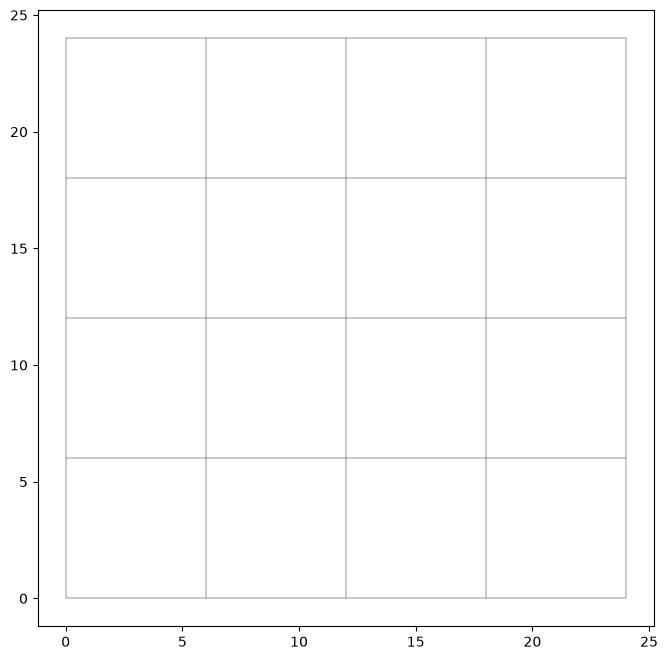

In [10]:
ds.plot_outline()


## Mapping the real results

The result variables carry a time axis (`time_values` shows the stored timesteps, in seconds). At `t = 0` the model is still dry (`Mesh2D_s1` is all fill value), so we select a later wet step with `isel(time=...)` before mapping.

In [11]:
print("timesteps (s):", ds.time_values)
step = ds.isel(time=3)  # t = 30 s, water present

timesteps (s): [np.float64(0.0), np.float64(10.0), np.float64(20.0), np.float64(30.0), np.float64(40.0), np.float64(50.0), np.float64(60.0)]


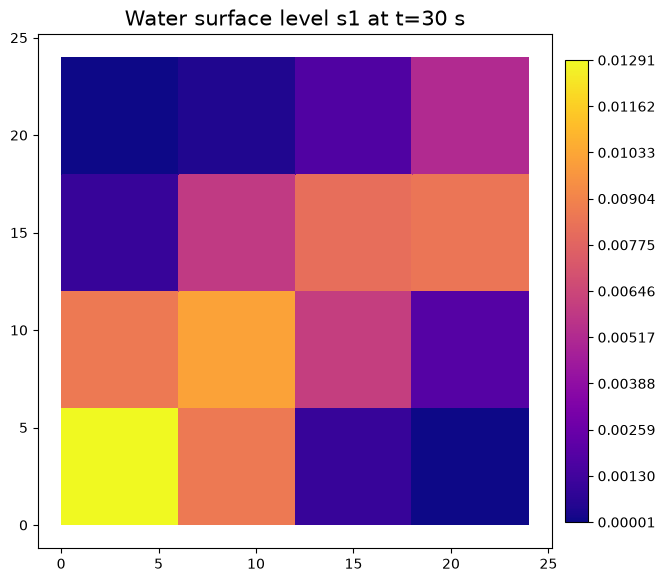

In [12]:
step.plot("Mesh2D_s1", cmap="plasma", colorbar=True, title="Water surface level s1 at t=30 s")


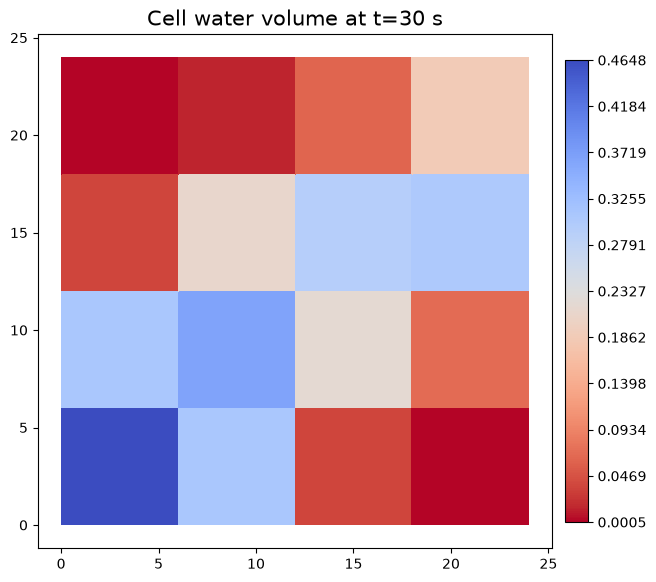

In [13]:
step.plot("Mesh2D_vol", cmap="viridis", colorbar=True, title="Cell water volume at t=30 s")


## From mesh to GIS

A `UgridDataset` is not a dead end - it converts into the vector and raster types the rest of a GIS workflow expects. Everything below is reached through pyramids; this package only supplies the file-format driver that built the mesh.

### Faces as vector polygons

`to_geodataframe(variable_name=...)` turns every face into a polygon row carrying that variable's value - a standard GeoPandas `GeoDataFrame` you can join, filter, or export.

In [14]:
gdf = step.to_geodataframe(variable_name="Mesh2D_s1")
print("rows:", len(gdf), " columns:", list(gdf.columns), " crs:", gdf.crs)
gdf.head()

rows: 16  columns: ['Mesh2D_s1', 'geometry']  crs: None


,Mesh2D_s1,geometry
0,0.012911,"POLYGON ((0 0, 6 0, 6 6, 0 6, 0 0))"
1,0.008589,"POLYGON ((0 6, 6 6, 6 12, 0 12, 0 6))"
2,0.000980,"POLYGON ((0 12, 6 12, 6 18, 0 18, 0 12))"
3,0.000014,"POLYGON ((0 18, 6 18, 6 24, 0 24, 0 18))"
4,0.008590,"POLYGON ((6 0, 12 0, 12 6, 6 6, 6 0))"


Plotting that `GeoDataFrame` straight through GeoPandas (matplotlib under the hood) gives a choropleth of the same values, now as independent vector features.

Text(0.5, 1.0, 'Mesh2D_s1 - per-face polygons')

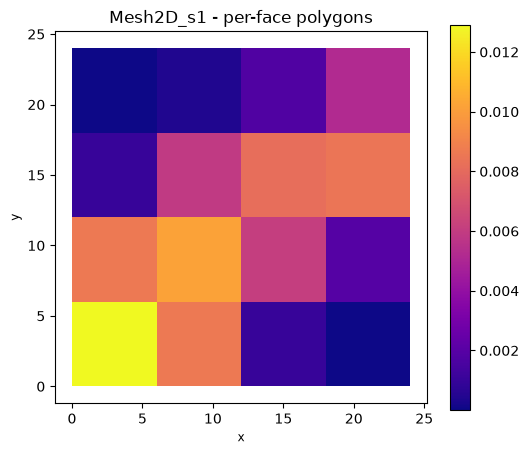

In [15]:
gdf.plot(column="Mesh2D_s1", cmap="plasma", legend=True, figsize=(6, 5))
plt.title("Mesh2D_s1 - per-face polygons")


### Dissolving into zones

`polygonize(variable)` merges neighbouring faces that share a value into larger polygons - handy for turning a noisy per-cell field into clean zones. It needs a single value per face, which is exactly what our working dataset holds.

dissolved polygons: 16  columns: ['value', 'geometry']


Text(0.5, 1.0, 'Dissolved value zones')

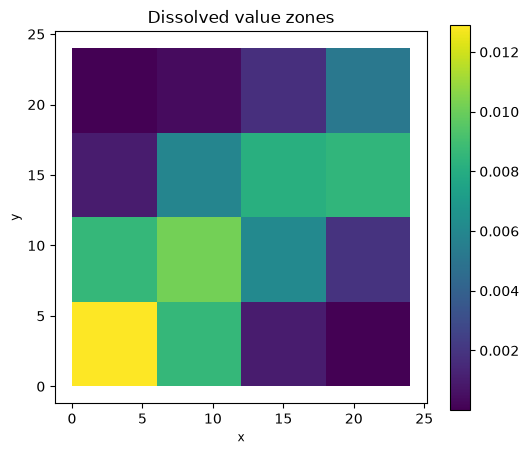

In [16]:
zones = step.polygonize("Mesh2D_s1")
print("dissolved polygons:", len(zones), " columns:", list(zones.columns))
zones.plot(column="value", cmap="viridis", legend=True, figsize=(6, 5))
plt.title("Dissolved value zones")


### Sampling at points

`sample(variable, x, y)` reads the value of the face that contains each query point. Here we probe the first few face centroids, so each query lands squarely inside a face.

In [17]:
cen = np.asarray(ds.mesh.face_centroids)
xs, ys = cen[0][:5], cen[1][:5]
vals = step.sample("Mesh2D_s1", xs, ys)
for x, y, v in zip(xs, ys, np.asarray(vals)):
    print(f"({x:10.2f}, {y:10.2f}) -> {float(v):.4f}")

(      3.00,       3.00) -> 0.0129
(      3.00,       9.00) -> 0.0086
(      3.00,      15.00) -> 0.0010
(      3.00,      21.00) -> 0.0000
(      9.00,       3.00) -> 0.0086


### The mesh outline as one polygon

`bounding_polygon()` returns a single shapely polygon tracing the mesh's outer boundary - the model's wetted footprint, useful as a clip mask or extent reference.

Text(0.5, 1.0, 'Mesh bounding polygon')

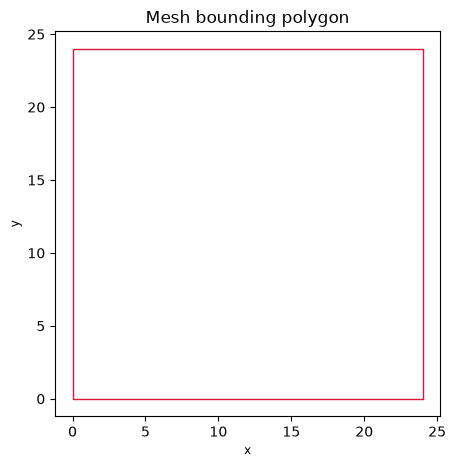

In [18]:
poly = ds.bounding_polygon()
import geopandas as gpd
gpd.GeoSeries([poly]).plot(facecolor="none", edgecolor="crimson", figsize=(5, 5))
plt.title("Mesh bounding polygon")


### Cropping to a sub-region

`subset_by_bounds(xmin, ymin, xmax, ymax)` returns a new, smaller `UgridDataset` holding only the faces inside the box - the same object type, so every operation above still applies. We derive a box from the mesh envelope so it works on any extent.

faces in full mesh: 16  -> in subset: 4


Text(0.5, 1.0, 'Lower-left quadrant subset')

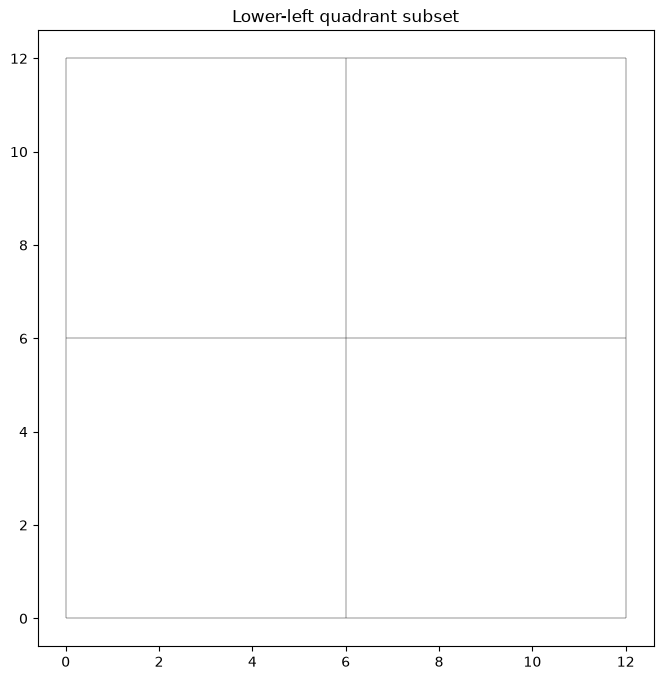

In [19]:
xmin, ymin, xmax, ymax = ds.bounds
mx, my = (xmin + xmax) / 2, (ymin + ymax) / 2
sub = ds.subset_by_bounds(xmin, ymin, mx, my)
print("faces in full mesh:", ds.n_face, " -> in subset:", sub.n_face)
sub.plot_outline()
plt.title("Lower-left quadrant subset")


### Connectivity as a sparse graph

`sparse_adjacency()` exposes face-to-face adjacency as a SciPy sparse matrix, and `connected_components()` labels each face by which connected piece of the mesh it belongs to - the entry points for graph algorithms over the grid.

In [20]:
adj = ds.sparse_adjacency()
print("adjacency:", adj.shape, " non-zeros:", adj.nnz)
labels = ds.connected_components()
print("connected components:", len(np.unique(np.asarray(labels))))

adjacency: (16, 16)  non-zeros: 48
connected components: 1


### Circumcenters - not applicable here

`circumcenters()` is only defined for purely triangular meshes. This grid contains quad (or mixed-polygon) faces, so the call would raise `ValueError`. We note it and skip rather than force it.

### Self-contained rasterisation

`to_dataset(variable, cell_size=...)` samples the mesh onto a regular raster grid and returns a pyramids `Dataset`. Unlike `rasterize_like` / `regrid` - which need an existing reference grid and are therefore skipped here - this is self-contained: you only choose a cell size.

rasterised to: Dataset


Text(0.5, 1.0, 'Mesh2D_s1 rasterised')

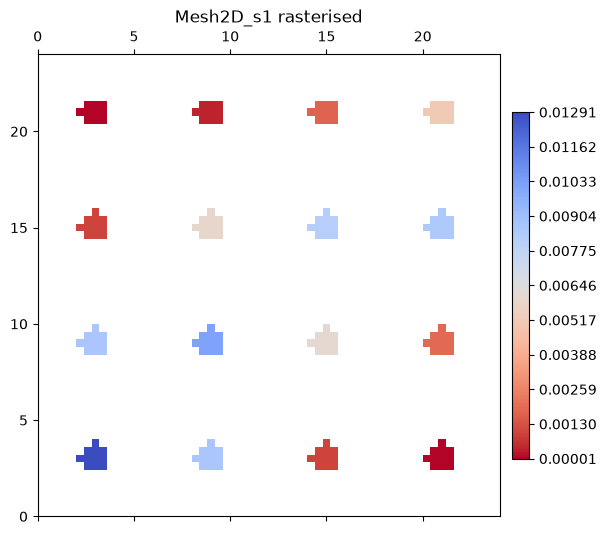

In [21]:
step_xy = (ds.bounds[2] - ds.bounds[0]) / 60
rast = step.to_dataset("Mesh2D_s1", cell_size=step_xy)
print("rasterised to:", type(rast).__name__)
rast.plot()
plt.title("Mesh2D_s1 rasterised")


### Reprojection - skipped

`to_crs(...)` needs a *source* CRS to project from. This 3Di result stores coordinates without a CRS, so `ds.crs` is `None`. With no source CRS, reprojection is undefined, so we skip it; assign a CRS first if your coordinates are georeferenced.

### Back to xarray

`to_xarray()` hands the whole dataset back as an `xarray.Dataset`, so you can drop into the full xarray ecosystem (time selection, resampling, NetCDF export) whenever you need it.

In [22]:
xds = ds.to_xarray()
type(xds).__name__, list(xds.data_vars)[:6]

('Dataset',
 ['mesh2d',
  'mesh2d_node_x',
  'mesh2d_node_y',
  'mesh2d_face_nodes',
  'mesh2d_face_x',
  'mesh2d_face_y'])

## Takeaway

The 3Di driver shows what a *needs-mesh* driver does: the file never stored an explicit polygon mesh, yet the driver reconstructs the 2D grid and serves it as an ordinary `UgridDataset`. Select a wet timestep with `isel`, then map water level and volume, convert faces to vectors, or crop - all through the shared pyramids API, with the 1D network reported-but-skipped rather than silently mangled.